# NMOS_OFF: why the mean error is high, and what was tried to lower it

Follow-up to `ML_Models/Notebooks/nmos_models.ipynb` (MLP 128-64-32-16 + Kirchhoff loss, random 80 / 10 / 10 split, seed 12175305).
Three questions:

1. **Why is the NMOS_OFF mean error (6.67 %) high while its median (0.40 %) is not, and how large is it in amperes?**
2. **Can a signed-log target lower it?** (`sign(I) · log10(1 + |I| / I0)` instead of `log10 |I|`)
3. **How does the model behave when the split is not random** — held-out widths (W / L), held-out temperatures, or both?

The training runs are made by `ML_Models/Scripts/run_offstudy.py` (code: `offstudy.py`, same features, scaling, optimizer and
network as the training notebooks); this notebook only reads their results (`Results/offstudy/`) and the saved models.
Everything uses the 20,000-sample NMOS_OFF dataset; nothing was removed from it.

**Findings**

* **A robust (Huber) loss lowers the typical error of every case and removes the seed lottery (section 5).** Same network and split: NMOS_OFF test median 0.40 / 1.08 / 0.62 % (MSE, three seeds) →
  0.25 / 0.32 / 0.27 % (Huber, transition width β = 0.05) → 0.13 / 0.13 % (β = 0.002, chosen on validation); 95th percentile 3.0 – 5.5 % → 1.0 – 1.2 %. PMOS_OFF, NMOS_ON and PMOS_ON improve as well (median 0.20 / 0.16 / 0.20 %).
  The mean stays at 3 – 6 %: one near-cancelled test row (SPICE |is| = 1.6e-13 A, error 1.2e4 – 6.5e4 % in every run) contributes 1.5 – 8 points of it.
* **Cause.** `id` and `is` of an OFF transistor are, at the terminal with the lower potential, the *difference* of two nearly equal
  terms (channel current leaving, gate / junction leakage entering). Where they almost cancel, a fixed absolute error of the order of
  0.1 % – 0.3 % of the row's largest current becomes a huge percentage. The absolute error does not grow there; the percentage does (section 1).
* **The mean is the wrong summary.** A bootstrap of the NMOS_OFF `id` mean over test-size samples spans 2 % – 46 %, while the
  median stays at 0.54 % – 0.60 % (section 1c). In amperes the mean absolute error is about 65 pA on currents averaging 7 nA,
  i.e. 0.9 % (section 2).
* **Signed-log target: no improvement.** The best of four settings lowered the test mean (6.9 % → 3.8 %) but raised the median
  3× (0.40 % → 1.2 %), the 95th percentile 2.8×, and the absolute error of `id` 4.7×; across seeds and splits it is worse far more often than better (sections 3, 4).
* **Training noise is large.** The test median of the same model and split moves between 0.35 % and 1.08 % with the training seed alone;
  an ensemble of the five seeds reproduces the best single seed (0.35 % / 2.2 %) but not a lower mean (section 3).
* **Structured splits** (section 4): interpolation costs nothing measurable beyond the seed noise: held-out W / L bands 0.52 / 1.97 / 0.52 % and held-out 10 °C windows
  1.98 / 0.64 / 0.51 % (three seeds each) against 0.35 – 1.08 % for the random split; widths even extrapolate (0.72 % at W / L 7 – 8). **Extrapolation in temperature is the failure:**
  at 105 – 125 °C `id`, `ig`, `is` have a median error of 4 – 6 % and the body current `ib` 41 % (it is under-predicted by 0.74× to 0.40×: `ib` is a flat 1e-14 A below 85 °C and rises only above about 90 °C, a regime the training set does not contain); in the wide-and-hot corner 6 – 11 % and 58 %.
  The two ON cases extrapolate well (0.5 – 2.4 %).

> **Note — final models.** This study was run when `ML_Models/Saved_Models/<case>.pt` held the earlier models of the training
> notebooks (MLP / MLP + Kirchhoff loss, trained with MSE; they remain in the git history, commit 603bc8b), so the outputs below
> that use "the saved models" or "official" refer to those. Its conclusion — the Huber loss (section 5) — made the Huber MLPs the
> final models: they are now `Saved_Models/<case>.pt` (the folder `Saved_Models/huber/` no longer exists). Re-running the sections
> that load the saved models therefore evaluates the final models.


In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / "Data_Generation").is_dir():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Open this notebook from inside the DVD-Project repo")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "ML_Models" / "Scripts"))
import offstudy as o
from leakage_model import LeakageModel, split_indices, OUTPUT_COLS

DATA_DIR, MODEL_DIR, PLOT_DIR = ROOT / "Data_Generation" / "Datasets", ROOT / "ML_Models" / "Saved_Models", ROOT / "ML_Models" / "Plots"
STUDY = ROOT / "ML_Models" / "Results" / "offstudy"
SEED = o.SEED
rng = np.random.default_rng(SEED)
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
pd.set_option("display.width", 200)

# Chart style (same as the other notebooks); categorical slots 1-3 of the reference palette
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, GRID, SURFACE, MUTED = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb", "#c9c8c3"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.titlecolor": INK, "axes.titlesize": 10, "font.size": 9, "legend.frameon": False,
})

## 1. Why is the NMOS_OFF mean error high?

Evidence from the dataset and from the *saved* models (`Saved_Models/NMOS_OFF.pt`, `PMOS_OFF.pt`), evaluated on the 4,000 held-out
rows (validation + test), which neither model was fitted to. PMOS_OFF is shown as the comparison case.

In [2]:
# Held-out rows (validation + test, 4,000 rows) of the SAVED models of the two OFF cases: the predictions are unbiased there
def heldout(case):
    df = pd.read_csv(DATA_DIR / f"{case}_20k.csv")
    _, iv, it = split_indices(len(df))
    h = df.iloc[np.r_[iv, it]].reset_index(drop=True)
    pred = LeakageModel(MODEL_DIR / f"{case}.pt").predict(h)          # |id|, |ig|, |is|, |ib|
    return h, h[OUTPUT_COLS].abs(), pred

FULL = {c: pd.read_csv(DATA_DIR / f"{c}_20k.csv") for c in ["NMOS_OFF", "PMOS_OFF"]}
H = {c: heldout(c) for c in FULL}
print({c: len(v[0]) for c, v in H.items()}, "held-out rows")

{'NMOS_OFF': 4000, 'PMOS_OFF': 4000} held-out rows


### 1a. Which current cancels, and where?

Table: for `id` and `is`, how often the current changes sign, and the conditions of the rows where it is below 1 % of the largest current of its row.
`ig` and `ib` never change sign. In every one of those near-cancelled rows the current belongs to the terminal that sits at the
**lower potential** (the effective source of an NMOS), and only that terminal ever changes sign. That is where the channel
(sub-threshold) current leaves the device while gate-tunnelling and junction leakage enter it (the reference slides of the course draw
exactly these directions), so the net current is `|I_other terminal| − ig − ib`, a difference of two positive terms.
The near-cancelled rows have a low source voltage (0.13 V on average against 0.30 V), a large `|vds|` (0.55 V against 0.30 V)
and lower temperatures (20 – 24 °C against 42 °C): conditions where the channel current is comparable to the gate leakage.

In [3]:
# 1a. Which terminal cancels, and under which conditions? (all 20,000 rows of the dataset - no model involved)
rows = []
for case, df in FULL.items():
    a = df[OUTPUT_COLS].abs()
    scale = a.max(axis=1)
    nm = case.startswith("NMOS")
    low_is_drain = (df["vd"] < df["vs"]) if nm else (df["vd"] > df["vs"])     # drain at the lower (NMOS) / higher (PMOS) potential
    eff_src_v = np.minimum(df["vd"], df["vs"]) if nm else (df["vdd"] - np.maximum(df["vd"], df["vs"]))
    for c, is_eff in (("id", low_is_drain), ("is", ~low_is_drain)):
        small = a[c] / scale < 0.01
        rows.append({
            "case": case, "current": c,
            "sign changes": bool((df[c] > 0).any() and (df[c] < 0).any()),
            "% positive when it is the effective-source terminal": 100 * (df.loc[is_eff, c] > 0).mean(),
            "% positive when it is the other terminal": 100 * (df.loc[~is_eff, c] > 0).mean(),
            "rows < 1 % of the largest current": int(small.sum()),
            "... of which at the effective-source terminal": int((small & is_eff).sum()),
            "mean temp, those rows (all rows) degC": f"{df.loc[small, 'temp'].mean():.0f} ({df['temp'].mean():.0f})",
            "mean |vds|, those rows (all) V": f"{(df.loc[small, 'vd'] - df.loc[small, 'vs']).abs().mean():.2f} "
                                             f"({(df['vd'] - df['vs']).abs().mean():.2f})",
            "mean effective-source V, those rows (all)": f"{eff_src_v[small].mean():.2f} ({eff_src_v.mean():.2f})"})
for case, df in FULL.items():
    for c in ("ig", "ib"):
        print(f"{case}: {c} is {'always positive' if (df[c] > 0).all() else 'always negative' if (df[c] < 0).all() else 'of both signs'}")
pd.DataFrame(rows).set_index(["case", "current"]).T

NMOS_OFF: ig is always positive
NMOS_OFF: ib is always positive
PMOS_OFF: ig is always negative
PMOS_OFF: ib is always negative


case                                                   NMOS_OFF                  PMOS_OFF             
current                                                      id           is           id           is
sign changes                                               True         True         True         True
% positive when it is the effective-source term...        29.38         29.4         69.6        69.79
% positive when it is the other terminal                      0            0          100          100
rows < 1 % of the largest current                           265          213          146          164
... of which at the effective-source terminal               265          213          146          164
mean temp, those rows (all rows) degC                   20 (42)      24 (42)      36 (42)      26 (42)
mean |vds|, those rows (all) V                      0.55 (0.30)  0.56 (0.30)  0.53 (0.30)  0.54 (0.30)
mean effective-source V, those rows (all)           0.13 (0.30)  0.13 (0.30)  0.15 (0.30)  0.15 (0.30)

### 1b. The absolute error does not shrink when the current cancels

If the network has a roughly constant absolute error (in proportion to the size of the terms being subtracted), the *relative* error of
the net current must grow as 1 / (|I| / largest current). The dashed line is exactly that, drawn with the median absolute error of the
all held-out rows (0.23 % of the row's largest current; in the cancelled rows the medians per bin are 0.04 % – 0.13 %); the points follow it. The table gives the same by bins. Rows with
|I| < 1 % of the largest current are 1.2 % of the NMOS_OFF `id` / `is` values. The median error of the held-out rows is 0.5 % when |I| is above 10 % of the largest current,
about 7 % between 0.1 % and 1 %, and about 880 % below 0.1 % (10 of the 8,000 held-out `id` / `is` values).

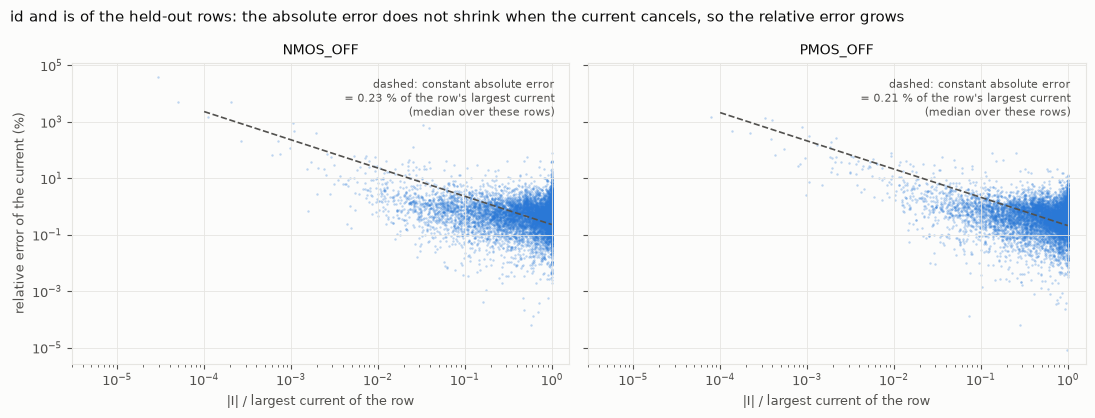

pairs  mean rel err %  median rel err %  median abs err / largest %
case     |I| / largest current                                                                     
NMOS_OFF 0 - 0.001                 10            9195             876.1                      0.1337
         0.001 - 0.01              68           40.48             6.777                     0.03504
         0.01 - 0.1               859           4.014            0.9447                     0.04326
         0.1 - 0.5               2451          0.8907            0.5177                      0.1332
         0.5 - 1.0001            4612          0.9645            0.5204                       0.411
PMOS_OFF 0 - 0.001                 13           474.3             243.6                     0.06438
         0.001 - 0.01              51           42.77             23.93                     0.09366
         0.01 - 0.1               637           2.436            0.9998                     0.04976
         0.1 - 0.5               2609          0.8498            0.4951                      0.1326
         0.5 - 1.0001            4690          0.7066            0.4296                      0.3371

In [4]:
# 1b. Relative error and absolute error vs how much of the row's current is left after the cancellation
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
SIZE_TABLE = []
for ax, case in zip(axes, H):
    h, true, pred = H[case]
    scale = true.max(axis=1)
    x = np.r_[true["id"] / scale, true["is"] / scale]
    ab = np.r_[(pred["id"] - true["id"]).abs() / scale, (pred["is"] - true["is"]).abs() / scale]      # abs error / row scale
    rel = ab / x * 100
    ax.scatter(x, rel, s=3, alpha=0.3, color=BLUE, linewidths=0, rasterized=True)
    k = np.median(ab) * 100
    xs = np.logspace(-4, 0, 50)
    ax.plot(xs, k / xs, ls="--", color=INK_2, lw=1.2)
    ax.text(0.97, 0.95, f"dashed: constant absolute error\n= {k:.2f} % of the row's largest current\n(median over these rows)",
            transform=ax.transAxes, ha="right", va="top", color=INK_2, fontsize=8)
    ax.set(xscale="log", yscale="log", xlim=(3e-6, 1.6), xlabel="|I| / largest current of the row", title=case)
    for lo, hi in [(0, 1e-3), (1e-3, 1e-2), (1e-2, 1e-1), (1e-1, 0.5), (0.5, 1.0001)]:
        s = (x >= lo) & (x < hi)
        if s.sum():
            SIZE_TABLE.append({"case": case, "|I| / largest current": f"{lo:g} - {hi:g}", "pairs": int(s.sum()),
                               "mean rel err %": rel[s].mean(), "median rel err %": np.median(rel[s]),
                               "median abs err / largest %": 100 * np.median(ab[s])})
axes[0].set_ylabel("relative error of the current (%)")
fig.suptitle("id and is of the held-out rows: the absolute error does not shrink when the current cancels, so the relative error grows",
             x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout()
fig.savefig(PLOT_DIR / "off_error_vs_current_size.png", dpi=150)
plt.show()
pd.DataFrame(SIZE_TABLE).set_index(["case", "|I| / largest current"])

### 1c. The mean is not a stable statistic

The error of a row grows as 1 / |I| near a sign change, so a few rows decide the mean. The bootstrap draws 2,000 rows (the size of a
test set) with replacement from the 4,000 held-out rows, 2,000 times. The NMOS_OFF `id` mean varies by a factor 20 – 25 between draws
(2 % – 46 %), the median by ±5 %. The reported 6.67 % is one draw from such a distribution. For PMOS_OFF the spread is narrower
(1.3 % – 4.2 %) but of the same kind. If the absolute error stays constant near a sign change and the net current has a finite density
there, the expectation of the percentage error is not even finite (it diverges logarithmically at 0), which is consistent with this.

In [5]:
# 1c. How stable is the mean? Bootstrap: draw 2,000 rows (the size of a test set) with replacement from the 4,000 held-out rows
rows = []
for case in H:
    h, true, pred = H[case]
    rel = (pred - true).abs() / true * 100
    for c in ("id", "is"):
        r = rel[c].to_numpy()
        means = np.array([rng.choice(r, 2000).mean() for _ in range(2000)])
        meds = np.array([np.median(rng.choice(r, 2000)) for _ in range(2000)])
        p = lambda v: " / ".join(f"{x:.3g}" for x in np.percentile(v, [5, 50, 95]))
        rows.append({"case": case, "current": c, "mean error % (5th / 50th / 95th of the bootstrap)": p(means),
                     "median error % (5th / 50th / 95th)": p(meds), "largest single error %": r.max()})
pd.DataFrame(rows).set_index(["case", "current"])

mean error % (5th / 50th / 95th of the bootstrap) median error % (5th / 50th / 95th)  largest single error %
case     current                                                                                                             
NMOS_OFF id                                     1.98 / 7.71 / 46.3              0.538 / 0.563 / 0.596               4.123e+04
         is                                      1.06 / 1.3 / 39.4              0.518 / 0.546 / 0.579               3.823e+04
PMOS_OFF id                                     1.27 / 2.45 / 4.17              0.461 / 0.483 / 0.504                    1537
         is                                     1.03 / 1.29 / 1.71              0.451 / 0.471 / 0.496                   473.1

### 1d. Error by operating condition (NMOS_OFF, `id` and `is`)

The **median** error is the same in every temperature, W / L, vth0 and VDD bin (0.47 % – 0.65 %); it only rises where the current is
cancelled: low source voltage (1.0 % below 0.1 V, 95th percentile 7 %). The **share of near-cancelled rows** is 2 – 3× higher
below 40 °C than above, and 0 % where the lower terminal voltage is above 0.3 V; it does not depend on W / L or vth0 (both scale all terms alike). The
mean per bin (2 % – 42 %) only reflects which bin holds the deepest rows: the 42 % in the lowest VDD bin is two rows (errors of 41,230 % and 38,235 %); without them that bin's mean is 1.3 %.

In [6]:
# 1d. Error by operating condition (NMOS_OFF held-out rows, id and is pooled)
h, true, pred = H["NMOS_OFF"]
rel = (pred - true).abs() / true * 100
scale = true.max(axis=1)
eff_v = np.minimum(h["vd"], h["vs"])
vds = (h["vd"] - h["vs"]).abs()
vth = h["vth0"].abs()
conds = {"temperature (degC)": (h["temp"], [-40, 0, 40, 85, 125.1]),
         "W / L": (h["w"] / o.L_MIN, [1, 2.75, 4.5, 6.25, 8.01]),
         "vth0 (V, quartiles)": (vth, list(np.quantile(vth, [0, .25, .5, .75])) + [vth.max() + 1e-9]),
         "VDD (V)": (h["vdd"], [0.81, 0.855, 0.9, 0.945, 0.9901]),
         "lower of vd, vs (V)": (eff_v, [0, 0.1, 0.3, 0.6, 1.0]),
         "|vd - vs| (V)": (vds, [0, 0.1, 0.3, 0.6, 1.0])}
tables = []
for name, (x, edges) in conds.items():
    b = pd.cut(x, edges, include_lowest=True, right=False)
    for lab in b.cat.categories:
        s = (b == lab).to_numpy()
        e = np.r_[rel.loc[s, "id"], rel.loc[s, "is"]]
        small = np.r_[true.loc[s, "id"] / scale[s] < .01, true.loc[s, "is"] / scale[s] < .01]
        tables.append({"condition": name, "bin": str(lab), "rows": int(s.sum()), "median %": np.median(e),
                       "95th pct %": np.percentile(e, 95), "mean %": e.mean(), "current < 1 % of largest (share %)": 100 * small.mean()})
pd.DataFrame(tables).set_index(["condition", "bin"])

rows  median %  95th pct %  mean %  current < 1 % of largest (share %)
condition           bin                                                                                   
temperature (degC)  [-40.0, 0.0)     937    0.5923       4.348    23.5                               1.441
                    [0.0, 40.0)      997    0.4734       3.244   3.329                               1.354
                    [40.0, 85.0)    1080    0.5332       2.963    5.93                              0.6481
                    [85.0, 125.1)    986     0.646       3.824   20.94                              0.5071
W / L               [1.0, 2.75)     1030     0.629        3.94   21.29                              0.7282
                    [2.75, 4.5)     1001     0.506       2.785   4.049                              0.8991
                    [4.5, 6.25)      986    0.5323       3.554   5.273                               1.318
                    [6.25, 8.01)     983    0.5599       3.379   21.57                              0.9664
vth0 (V, quartiles) [0.308, 0.326)  1000    0.5897       3.906   4.926                                 1.1
                    [0.326, 0.342)  1000    0.5081       3.032   20.45                                0.65
                    [0.342, 0.36)   1000    0.5331       3.255   23.03                                0.95
                    [0.36, 0.377)   1000    0.6091       3.672   3.993                                 1.2
VDD (V)             [0.81, 0.855)    982    0.5329       3.587   41.78                                1.12
                    [0.855, 0.9)    1027    0.5429       3.078   4.992                               0.779
                    [0.9, 0.945)     994    0.5434       3.455   4.052                               1.006
                    [0.945, 0.99)    997    0.6123       3.755   2.211                               1.003
lower of vd, vs (V) [0.0, 0.1)       879     1.003       6.976   26.68                               1.024
                    [0.1, 0.3)      1362    0.6305       4.461   20.56                               2.203
                    [0.3, 0.6)      1319    0.4057       1.382  0.5198                                   0
                    [0.6, 1.0)       440    0.4297        1.43  0.5532                                   0
|vd - vs| (V)       [0.0, 0.1)       840    0.6038       5.877   2.595                             0.05952
                    [0.1, 0.3)      1427    0.4821       2.854   16.75                              0.3153
                    [0.3, 0.6)      1276     0.541       2.784   19.42                               1.293
                    [0.6, 1.0)       457    0.8374       3.918   3.356                               3.829

## 2. How large is the error in amperes?

Saved models, official test set (2,000 rows). A mean percentage error of 6.67 % corresponds to a **mean absolute error of 65 pA for `id` and
`is`** (currents averaging 7 nA, median 2 nA), 37 pA for `ig`, 0.06 fA for `ib`: **0.9 %, 0.5 % and 0.5 %** of the mean current. Weighted by current
(sum of the absolute errors over the sum of the currents) the NMOS_OFF error is 0.76 %. The worst test row has a 38,000 % error:
the SPICE `is` is 1.6e-13 A, the model gives 6.0e-11 A — an error of 60 pA, 1.1 % of the 5.3 nA in that row's largest current.

In [7]:
# 2. Error in amperes, saved models, official test set (2,000 rows)
rows = []
for case in ["NMOS_OFF", "PMOS_OFF", "NMOS_ON", "PMOS_ON"]:
    df = pd.read_csv(DATA_DIR / f"{case}_20k.csv")
    _, _, it = split_indices(len(df))
    t = df.iloc[it].reset_index(drop=True)
    pred = LeakageModel(MODEL_DIR / f"{case}.pt").predict(t)
    true = t[OUTPUT_COLS].abs()
    err = (pred - true).abs()
    for c in OUTPUT_COLS:
        rows.append({"case": case, "current": c, "mean |I| (A)": true[c].mean(),
                     "mean rel err %": (err[c] / true[c]).mean() * 100, "median rel err %": (err[c] / true[c]).median() * 100,
                     "mean abs err (A)": err[c].mean(), "median abs err (A)": err[c].median(), "max abs err (A)": err[c].max(),
                     "mean abs err / mean |I| %": 100 * err[c].mean() / true[c].mean()})
AMPS = pd.DataFrame(rows).set_index(["case", "current"])
AMPS.style.format({c: "{:.3g}" for c in AMPS.columns})

In [8]:
# Worst NMOS_OFF test rows in amperes: huge percentage, tiny absolute error
df = pd.read_csv(DATA_DIR / "NMOS_OFF_20k.csv")
_, _, it = split_indices(len(df))
t = df.iloc[it].reset_index(drop=True)
pred = LeakageModel(MODEL_DIR / "NMOS_OFF.pt").predict(t)
true = t[OUTPUT_COLS].abs()
scale = true.max(axis=1)
rows = []
for c in ("id", "is"):
    err = (pred[c] - true[c]).abs()
    for r in (err / true[c]).sort_values(ascending=False).index[:3]:
        rows.append({"current": c, "rel err %": 100 * err[r] / true[c][r], "|I| SPICE (A)": true[c][r], "|I| ML (A)": pred[c][r],
                     "abs err (A)": err[r], "largest |I| of the row (A)": scale[r], "abs err / largest %": 100 * err[r] / scale[r]})
pd.DataFrame(rows).set_index("current")

,rel err %,|I| SPICE (A),|I| ML (A),abs err (A),largest |I| of the row (A),abs err / largest %
current,,,,,,
id,5284,1.144e-13,6.16e-12,6.045e-12,2.295e-09,0.2634
id,791.2,5.979e-12,5.329e-11,4.731e-11,1.828e-10,25.88
id,617.9,1.483e-12,1.065e-11,9.163e-12,3.835e-11,23.89
is,3.823e+04,1.571e-13,6.023e-11,6.007e-11,5.289e-09,1.136
is,79.7,1.828e-10,3.71e-11,1.457e-10,1.828e-10,79.7
is,51.78,1.421e-11,2.157e-11,7.359e-12,2.025e-09,0.3634


## 3. Signed-log target

Target for `id` and `is` (the two currents that change sign): `sign(I) · log10(1 + |I| / I0)`, with I0 the q-quantile of |I| over the training rows;
`ig` and `ib` stay `log10 |I|`. The target is smooth through I = 0 and the model also predicts the sign. q was searched over
{0.001, 0.01, 0.05, 0.2} on the validation set with the notebooks' rule (lowest validation mean error), giving q = 0.05.
Same network, optimizer and split as the baseline; seed 12175305 unless stated. Errors: *mean / median / 95th* are the
notebooks' | |I_pred| / |I_true| − 1 | (sign ignored), *floored mean* is |I_pred − I_true| / max(|I_true|, 1 % of the row's largest current),
*sum err* is Σ|I_pred − I_true| / Σ|I_true| (the ampere-weighted error).

In [9]:
def load_runs():
    rows = []
    for p in sorted((STUDY / "runs").glob("*.json")):
        r = json.loads(p.read_text())
        row = {k: r[k] for k in ("case", "scheme", "target", "q", "lam", "seed", "epochs", "n_train", "n_val", "n_test")}
        row["patience"] = r.get("patience", 300)
        row["hidden"] = "-".join(map(str, r.get("hidden", o.HIDDEN)))
        row["loss_kind"], row["sched_kind"], row["select"] = r.get("loss_kind", "mse"), r.get("sched_kind", "plateau"), r.get("select", "loss")
        row["huber_beta"] = r.get("huber_beta", 0.05)
        for part in ("train", "val", "test"):
            a = r[part]["average"]
            for m in ("mean err %", "median err %", "95th pct err %", "signed mean err %", "floored mean err %", "sum err %", "R2 (log|I|)"):
                row[f"{part} {m}"] = a[m]
            for c in ("id", "is"):
                row[f"{part} {c} mean err %"] = r[part][c]["mean err %"]
                row[f"{part} {c} mean abs err (A)"] = r[part][c]["mean abs err (A)"]
                row[f"{part} {c} sign acc %"] = r[part][c]["sign acc %"]
        rows.append(row)
    d = pd.DataFrame(rows)
    d["method"] = np.where(d["target"] == "log", "log10|I|", "signed-log q=" + d["q"].astype(str))
    d.loc[d["lam"] > 0, "method"] += " + Kirchhoff"
    d["full"] = d["epochs"] >= o.MLP_PARAMS["max_epochs"]       # trained all 3000 epochs (early stopping never triggered)
    d["variant"] = (d["method"] + np.where(d["loss_kind"] != "mse", " + Huber loss, beta " + d["huber_beta"].astype(str), "") + np.where(d["sched_kind"] != "plateau", " + cosine schedule", "")
                    + np.where(d["select"] != "loss", " + epoch chosen by validation median", ""))
    return d


def full_run(case, scheme, target, q, seed):
    """Tag of the run of this configuration that trained all 3000 epochs (patience 300 if it got there, else patience 3000)."""
    for pat in (300, 3000):
        tag = o.run_tag(case, scheme, target, q, 0.0, seed, patience=pat)
        p = STUDY / "runs" / f"{tag}.json"
        if p.exists() and json.loads(p.read_text())["epochs"] >= o.MLP_PARAMS["max_epochs"]:
            return tag

RUNS_ALL = load_runs()
# Sections 3 and 4 are the MSE-loss protocol of the training notebooks; the Huber / cosine / learning-curve runs of section 5 are kept apart
RUNS = RUNS_ALL[(RUNS_ALL["loss_kind"] == "mse") & (RUNS_ALL["sched_kind"] == "plateau") & (RUNS_ALL["select"] == "loss")
                & ~((RUNS_ALL["scheme"] == "random") & (RUNS_ALL["n_train"] < 16000))].copy()
print(len(RUNS_ALL), "runs in total,", len(RUNS), "with the notebooks' MSE loss")
base = RUNS[(RUNS.case == "NMOS_OFF") & (RUNS.scheme == "random") & (RUNS.seed == SEED) & (RUNS.hidden == "128-64-32-16") & (RUNS.patience == 300)].copy()
cols = ["method", "epochs", "val mean err %", "val median err %", "test mean err %", "test median err %", "test 95th pct err %",
        "test floored mean err %", "test sum err %", "test id mean abs err (A)", "test id sign acc %", "test is sign acc %", "train median err %"]
base["order"] = base["method"].map(lambda m: (m != "log10|I|", m))
base.sort_values("order")[cols].set_index("method")

89 runs in total, 65 with the notebooks' MSE loss


,epochs,val mean err %,val median err %,test mean err %,test median err %,test 95th pct err %,test floored mean err %,test sum err %,test id mean abs err (A),test id sign acc %,test is sign acc %,train median err %
method,,,,,,,,,,,,
log10|I|,3000,8.516,0.3968,6.89,0.4032,2.969,1.413,0.6565,5.291e-11,100,100,0.3517
log10|I| + Kirchhoff,642,9.185,1.301,15.77,1.304,6.751,2.392,2.155,1.885e-10,100,100,1.255
signed-log q=0.001,449,21.36,4.039,6.863,4.008,21.35,6.321,7.192,7.732e-10,99.55,99.9,3.899
signed-log q=0.01,436,14.36,3.43,7.174,3.476,18.13,5.67,5.637,6.896e-10,99.65,99.7,3.351
signed-log q=0.05,720,3.544,1.162,3.769,1.196,8.41,2.628,2.422,2.492e-10,99.7,99.85,1.125
signed-log q=0.2,451,6.938,2.242,20.16,2.294,17,5.821,3.575,3.725e-10,99.15,99.35,2.237


### 3a. Seed-to-seed variation and the effect of early stopping

Every NMOS_OFF run on the random split. "3000 epochs" = early stopping never ended the run. The same model and split give a test median anywhere between
0.35 % and 1.08 % depending on the training seed, and runs that early-stop (patience 300) end at 0.8 % – 2.1 %. Some seeds improve when early stopping is
disabled (seed 12175307: 2.13 % → 0.62 %), others do not (their validation minimum is early and never beaten). Signed-log is equally noisy
(0.62 % – 4.6 % over three seeds). Differences of less than a factor of about 3 between single runs are therefore not conclusive, and all comparisons
below use runs that trained the full 3000 epochs.

In [10]:
# Every NMOS_OFF run on the random split (same split and settings; they differ in the training seed, and whether early stopping ended them)
sel = RUNS[(RUNS.case == "NMOS_OFF") & (RUNS.scheme == "random") & (RUNS.lam == 0) & (RUNS.hidden == "128-64-32-16")
           & (RUNS.method.isin(["log10|I|", "signed-log q=0.05"]))].copy()
sel["run ended by"] = np.where(sel["full"], "3000 epochs", "early stopping")
cols = ["epochs", "test median err %", "test 95th pct err %", "test mean err %", "test floored mean err %", "test sum err %",
        "test id mean abs err (A)", "train median err %"]
display(sel.sort_values(["method", "seed", "patience"]).set_index(["method", "seed", "run ended by"])[cols])

# summary by method and how the run ended
g = sel.groupby(["method", "run ended by"])[["test median err %", "test 95th pct err %", "test mean err %", "test sum err %"]].agg(["min", "max"])
g.insert(0, ("runs", ""), sel.groupby(["method", "run ended by"]).size())
g

epochs  test median err %  test 95th pct err %  test mean err %  test floored mean err %  test sum err %  test id mean abs err (A)  train median err %
method            seed     run ended by                                                                                                                                                          
log10|I|          12175305 3000 epochs       3000             0.4032                2.969             6.89                    1.413          0.6565                 5.291e-11              0.3517
                  12175306 early stopping     662              1.077                5.454            7.079                    1.874           1.648                 1.569e-10               1.013
                           3000 epochs       3000              1.077                5.454            7.079                    1.874           1.648                 1.569e-10               1.013
                  12175307 early stopping     439              2.127                10.66            7.609                    3.457           3.533                 2.895e-10               2.058
                           3000 epochs       3000             0.6161                3.835            10.37                    1.454           1.048                 9.316e-11              0.5394
                  12175308 early stopping     911             0.8004                4.681            11.22                    1.687           1.212                 1.116e-10              0.7255
                           3000 epochs       3000             0.8004                4.681            11.22                    1.687           1.212                 1.116e-10              0.7255
                  12175309 3000 epochs       3000             0.3508                2.557             6.43                   0.9405          0.6459                 5.941e-11              0.3084
signed-log q=0.05 12175305 early stopping     720              1.196                 8.41            3.769                    2.628           2.422                 2.492e-10               1.125
                           3000 epochs       3000              1.196                 8.41            3.769                    2.628           2.422                 2.492e-10               1.125
                  12175306 early stopping     402              4.614                24.44            15.35                    7.713           6.936                 7.232e-10               4.573
                           3000 epochs       3000              4.614                24.44            15.35                    7.713           6.936                 7.232e-10               4.573
                  12175307 3000 epochs       3000             0.6195                5.306            8.514                    2.234           1.083                 1.043e-10              0.5662

runs test median err %       test 95th pct err %       test mean err %       test sum err %      
                                                    min   max                 min   max             min   max            min   max
method            run ended by                                                                                                    
log10|I|          3000 epochs       5            0.3508 1.077               2.557 5.454            6.43 11.22         0.6459 1.648
                  early stopping    3            0.8004 2.127               4.681 10.66           7.079 11.22          1.212 3.533
signed-log q=0.05 3000 epochs       3            0.6195 4.614               5.306 24.44           3.769 15.35          1.083 6.936
                  early stopping    2             1.196 4.614                8.41 24.44           3.769 15.35          2.422 6.936

In [11]:
# Ensembles of the runs that trained all 3000 epochs: geometric mean of the predicted magnitudes (the sign of the log models is the true one)
rows, cols = [], ["median err %", "95th pct err %", "mean err %", "floored mean err %", "sum err %"]
for method, target, q in (("log10|I|", "log", 0.01), ("signed-log q=0.05", "signedlog", 0.05)):
    tags = [t for t in (full_run("NMOS_OFF", "random", target, q, SEED + k) for k in range(5)) if t]
    if not tags:
        continue
    Z = [np.load(STUDY / "preds" / f"{t}.npz") for t in tags]
    T = Z[0]["test_true"].astype(float)
    P = np.stack([z["test"].astype(float) for z in Z])
    for t, p in zip(tags, P):
        rows.append({"model": f"{method}: seed {t.split('seed')[1][:8]}", **o.evaluate(T, p).loc["average"][cols]})
    if len(tags) > 1:
        ens = np.exp(np.log(np.abs(P)).mean(0)) * np.sign(P[0] if target == "signedlog" else T)
        rows.append({"model": f"{method}: ensemble of {len(tags)}", **o.evaluate(T, ens).loc["average"][cols]})
ENS = pd.DataFrame(rows).set_index("model")
ENS

,median err %,95th pct err %,mean err %,floored mean err %,sum err %
model,,,,,
log10|I|: seed 12175305,0.4032,2.969,6.89,1.413,0.6565
log10|I|: seed 12175306,1.077,5.454,7.079,1.874,1.648
log10|I|: seed 12175307,0.6161,3.835,10.37,1.454,1.048
log10|I|: seed 12175308,0.8004,4.681,11.22,1.687,1.212
log10|I|: seed 12175309,0.3508,2.557,6.43,0.9405,0.6459
log10|I|: ensemble of 5,0.348,2.2,7.475,0.9479,0.5854
signed-log q=0.05: seed 12175305,1.196,8.41,3.769,2.628,2.422
signed-log q=0.05: seed 12175306,4.614,24.44,15.35,7.713,6.936
signed-log q=0.05: seed 12175307,0.6195,5.306,8.514,2.234,1.083


In [12]:
# Bigger networks (log10|I| target, patience 300, same seed)
d = RUNS[(RUNS.case == "NMOS_OFF") & (RUNS.scheme == "random") & (RUNS.target == "log") & (RUNS.lam == 0) & (RUNS.seed == SEED)]
d.assign(parameters=d["hidden"].map(lambda h: sum(a * b + b for a, b in zip([25] + [int(x) for x in h.split("-")], [int(x) for x in h.split("-")] + [4]))))  .set_index("hidden")[["parameters", "epochs", "val median err %", "test median err %", "test 95th pct err %", "test mean err %", "test sum err %"]]

,parameters,epochs,val median err %,test median err %,test 95th pct err %,test mean err %,test sum err %
hidden,,,,,,,
128-64-32-16,14260,3000,0.3968,0.4032,2.969,6.89,0.6565
256-128-64-32,50020,791,0.8954,0.8766,4.784,13.83,1.374
256-256-128-64,113860,3000,0.4391,0.4377,4.921,44.5,1.255


### 3b. Direct prediction vs deriving the cancelling current

A natural alternative is to predict the three well-behaved currents and obtain the cancelling one from Kirchhoff's law, `−(other terminal + ig + ib)`.
It is 3× worse (median absolute error 0.36 % against 0.13 % of the row's largest current): the network predicts the cancelling terminal better than the
propagated errors of the other currents would allow, so that structure has already been learned. Predicted-vs-SPICE for the cancelling terminal
in the rows where it is below 10 % of the row's largest current follows.

In [13]:
# The cancelling terminal (id when vd < vs, else is): direct prediction vs "derive it from Kirchhoff's law"
df = FULL["NMOS_OFF"]
z = np.load(STUDY / "preds" / f"NMOS_OFF__random__log__lam0__seed{SEED}.npz")
rows = []
for part in ("val", "test"):
    P, T, idx = z[part].astype(float), z[f"{part}_true"].astype(float), z[f"{part}_idx"]
    d = df.iloc[idx]
    lo_is_id = d["vd"].to_numpy() < d["vs"].to_numpy()
    k_lo, k_hi, r = np.where(lo_is_id, 0, 2), np.where(lo_is_id, 2, 0), np.arange(len(idx))
    truth = T[r, k_lo]
    scale = np.abs(T).max(1)
    for name, v in (("direct (what the model predicts)", P[r, k_lo]), ("derived: -(other terminal + ig + ib)", -(P[r, k_hi] + P[:, 1] + P[:, 3]))):
        e, ab = np.abs(v / truth - 1) * 100, np.abs(v - truth)
        rows.append({"set": part, "estimate of the cancelling terminal": name, "median err %": np.median(e),
                     "95th pct err %": np.percentile(e, 95), "mean err %": e.mean(),
                     "mean abs err (A)": ab.mean(), "median abs err / largest %": 100 * np.median(ab / scale)})
pd.DataFrame(rows).set_index(["set", "estimate of the cancelling terminal"])

median err %  95th pct err %  mean err %  mean abs err (A)  median abs err / largest %
set  estimate of the cancelling terminal                                                                                         
val  direct (what the model predicts)            0.6441           5.414       31.15         4.325e-11                      0.1252
     derived: -(other terminal + ig + ib)         1.508           31.35       135.4         7.413e-11                      0.3676
test direct (what the model predicts)            0.6623           6.099        24.9         4.337e-11                      0.1281
     derived: -(other terminal + ig + ib)         1.429           38.56       89.85          6.85e-11                      0.3635

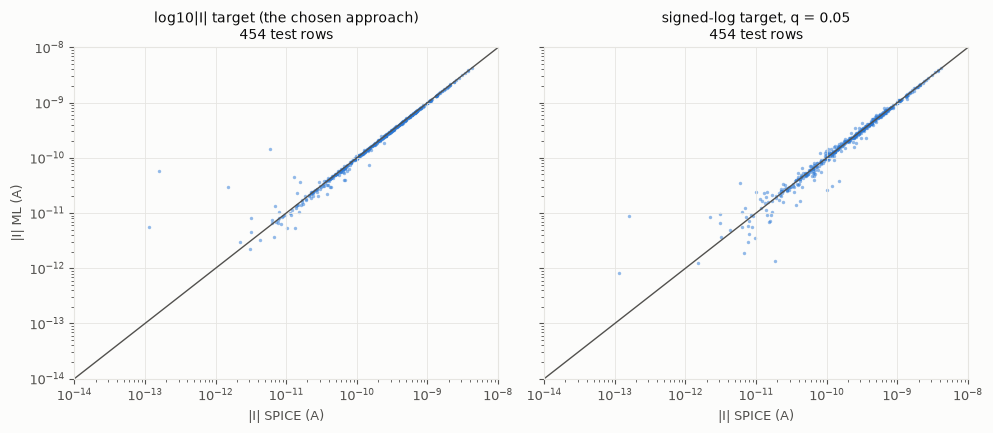

In [14]:
# Predicted vs SPICE for the cancelling terminal, rows where it is below 10 % of the row's largest current (test rows)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharex=True, sharey=True)
df = FULL["NMOS_OFF"]
for ax, (label, tag) in zip(axes, [("log10|I| target (the chosen approach)", f"NMOS_OFF__random__log__lam0__seed{SEED}"),
                                   ("signed-log target, q = 0.05", f"NMOS_OFF__random__signedlog_q0.05__lam0__seed{SEED}")]):
    z = np.load(STUDY / "preds" / f"{tag}.npz")
    P, T, idx = z["test"].astype(float), z["test_true"].astype(float), z["test_idx"]
    d = df.iloc[idx]
    k = np.where(d["vd"].to_numpy() < d["vs"].to_numpy(), 0, 2)
    r = np.arange(len(idx))
    truth, p = np.abs(T[r, k]), np.abs(P[r, k])
    small = truth / np.abs(T).max(1) < 0.1
    ax.scatter(truth[small], np.clip(p[small], 1e-16, None), s=6, alpha=0.5, color=BLUE, linewidths=0)
    lim = [1e-14, 1e-8]
    ax.plot(lim, lim, color=INK_2, lw=1)
    ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="|I| SPICE (A)", title=f"{label}\n{int(small.sum())} test rows")
axes[0].set_ylabel("|I| ML (A)")
fig.tight_layout()
fig.savefig(PLOT_DIR / "nmos_off_cancelling_terminal_parity.png", dpi=150)
plt.show()

## 4. Structured splits

The assignment asks for a random split; this section asks how well the model does on conditions it was *not* trained on. L is fixed at 45 nm,
so the "W / L" sets are width bands. Temperature windows around 27 °C and 85 °C are used as the "specific temperature values".
Training uses the same settings as before; every run trains 3000 epochs and keeps the best validation epoch (no early stopping; see 3a).
The validation set (used for the best epoch) is held out the same way as the test set, from different bands.

| Scheme | Train | Validation | Test |
|---|---|---|---|
| `random` | random 80 % | random 10 % | random 10 % |
| `W_interp` | all other widths | W / L in [2, 2.5), [4.5, 5) | W / L in [3, 3.5), [6, 6.5) |
| `W_extrap` | W / L < 6 | [6, 7) | [7, 8] |
| `T_interp` | all other temperatures | [−10, 0), [55, 65) °C | [22, 32) (room temperature), [80, 90) °C |
| `T_extrap` | T < 85 °C | [85, 105) °C | ≥ 105 °C |
| `WT_blocks` | 12 of 16 blocks of a 4 × 4 W / L × T grid | 2 blocks | 2 blocks (every W band and T band is seen in training, only the combination is new) |
| `WT_corner` | W / L < 6 and T < 85 °C | the shell just outside (W / L < 7, T < 105 °C) | wide and hot: W / L ≥ 7 and T ≥ 105 °C (361 rows) |

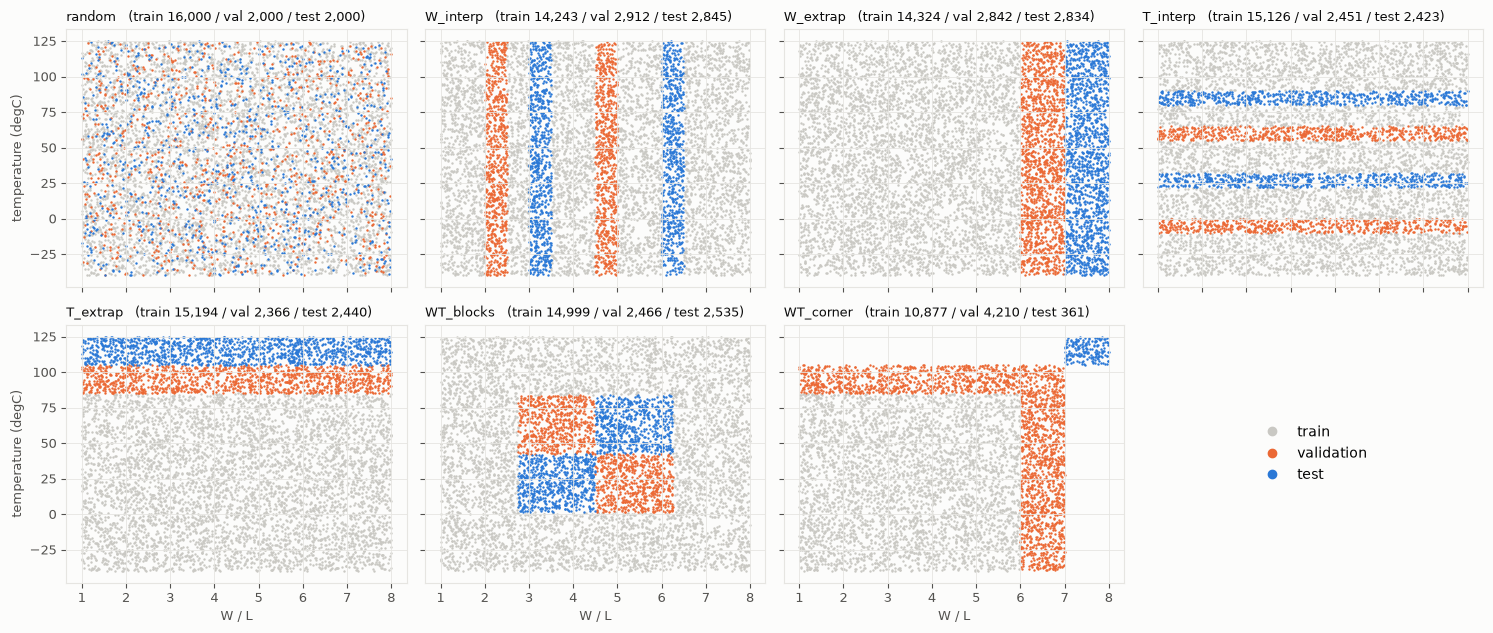

In [15]:
# The splits: every scheme in the (W / L, temperature) plane
dfo = FULL["NMOS_OFF"]
wl, T_ = (dfo["w"] / o.L_MIN).to_numpy(), dfo["temp"].to_numpy()
fig, axes = plt.subplots(2, 4, figsize=(15, 6.4), sharex=True, sharey=True)
for ax, scheme in zip(axes.flat, o.SCHEMES):
    tr, va, te = o.make_split(scheme, dfo)
    for idx, color, name in ((tr, MUTED, "train"), (va, ORANGE, "validation"), (te, BLUE, "test")):
        sub = idx[::3] if name == "train" else idx[::2]
        ax.scatter(wl[sub], T_[sub], s=3, color=color, linewidths=0, rasterized=True)
    ax.set_title(f"{scheme}   (train {len(tr):,} / val {len(va):,} / test {len(te):,})", loc="left", fontsize=9)
axes.flat[-1].axis("off")
axes.flat[-1].legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c, label=n) for c, n in
                              ((MUTED, "train"), (ORANGE, "validation"), (BLUE, "test"))], loc="center", fontsize=10)
for ax in axes[-1, :3]:
    ax.set_xlabel("W / L")
for ax in axes[:, 0]:
    ax.set_ylabel("temperature (degC)")
fig.tight_layout()
fig.savefig(PLOT_DIR / "offstudy_splits.png", dpi=130)
plt.show()

### 4a. NMOS_OFF on every split

Test errors (average over the four currents; the last column divides the median by that of the random split). One training seed (12175305); section 4b repeats the two interpolation splits with three seeds, which matters: with one seed `T_interp` looks 5× worse than the random split.

In [16]:
# Structured splits, NMOS_OFF. Main table: runs that trained all 3000 epochs (see section 3: early-stopped runs are not comparable)
METHODS = ["log10|I|", "signed-log q=0.05"]
S = RUNS[(RUNS.case == "NMOS_OFF") & (RUNS.seed == SEED) & (RUNS.lam == 0) & (RUNS.hidden == "128-64-32-16") & RUNS.method.isin(METHODS) & RUNS.full].copy()
ref = S[(S.scheme == "random") & (S.method == "log10|I|")].iloc[0]
tab = S.copy()
tab["scheme"] = pd.Categorical(tab["scheme"], o.SCHEMES, ordered=True)
tab["test median vs random split"] = tab["test median err %"] / ref["test median err %"]
cols = ["n_train", "n_test", "epochs", "val median err %", "test median err %", "test 95th pct err %", "test mean err %",
        "test floored mean err %", "test sum err %", "test median vs random split"]
display(tab.sort_values(["scheme", "method"]).set_index(["scheme", "method"])[cols])

n_train  n_test  epochs  val median err %  test median err %  test 95th pct err %  test mean err %  test floored mean err %  test sum err %  test median vs random split
scheme    method                                                                                                                                                                                     
random    log10|I|             16000    2000    3000            0.3968             0.4032                2.969             6.89                    1.413          0.6565                            1
          signed-log q=0.05    16000    2000    3000             1.162              1.196                 8.41            3.769                    2.628           2.422                        2.965
W_interp  log10|I|             14243    2845    3000            0.5327             0.5189                3.079             6.79                    1.067          0.8108                        1.287
          signed-log q=0.05    14243    2845    3000             2.823              2.641                15.77            7.228                    4.476            4.82                         6.55
W_extrap  log10|I|             14324    2834    3000            0.5924             0.7243                5.198            7.734                      1.6           1.242                        1.797
          signed-log q=0.05    14324    2834    3000             4.287              5.032                24.48             9.26                    7.645           7.981                        12.48
T_interp  log10|I|             15126    2423    3000               1.7              1.984                 9.16            3.662                    2.768           2.621                        4.921
          signed-log q=0.05    15126    2423    3000             5.026              4.949                19.52            8.064                    6.924           6.107                        12.27
T_extrap  log10|I|             15194    2440    3000             4.973              14.18                41.81            62.72                    9.157           22.08                        35.16
          signed-log q=0.05    15194    2440    3000             6.066              14.96                46.76            31.32                    9.218           24.21                        37.12
WT_blocks log10|I|             14999    2535    3000             4.665               4.62                17.31            8.294                    6.046            6.74                        11.46
          signed-log q=0.05    14999    2535    3000             2.762              2.775                15.92            6.258                    4.695           3.922                        6.882
WT_corner log10|I|             10877     361    3000              1.69              20.92                55.04            85.95                    12.42           26.39                        51.88
          signed-log q=0.05    10877     361    3000              3.25              19.79                70.78            32.39                    12.82           43.04                        49.08

### 4b. Is a difference between splits more than seed noise?

The held-out median per training seed for the random split and the two interpolation splits (log target, 3000 epochs). The spread between seeds of one split (0.35 – 1.08 % for random, 0.52 – 1.97 % for W_interp,
0.51 – 1.98 % for T_interp) is as large as the differences between the splits, so interpolation across a band of widths or temperatures is not measurably harder than a random split. Differences of the size of the extrapolation
results (14 % – 24 %) are far outside it.

In [17]:
# Seed check (log10|I| target, trained 3000 epochs): the held-out median per training seed for the random split and the two interpolation splits
Q = RUNS[(RUNS.case == "NMOS_OFF") & (RUNS.target == "log") & (RUNS.lam == 0) & (RUNS.hidden == "128-64-32-16") & RUNS.full
         & RUNS.scheme.isin(["random", "W_interp", "T_interp"])].copy()
Q["scheme"] = pd.Categorical(Q["scheme"], ["random", "W_interp", "T_interp"], ordered=True)
Q = Q.sort_values(["scheme", "seed"]).drop_duplicates(["scheme", "seed"])
seedtab = Q.pivot(index="seed", columns="scheme", values="test median err %")
seedtab.loc["min"], seedtab.loc["max"] = seedtab.min(), seedtab.max()
seedtab

scheme,random,W_interp,T_interp
seed,,,
12175305,0.4032,0.5189,1.984
12175306,1.077,1.965,0.6442
12175307,0.6161,0.5178,0.506
12175308,0.8004,NaN,NaN
12175309,0.3508,NaN,NaN
min,0.3508,0.5178,0.506
max,1.077,1.965,1.984


In [18]:
# The same table for the early-stopped runs (patience 300, as in the training notebooks): the result then depends on when training stalled
E = RUNS[(RUNS.case == "NMOS_OFF") & (RUNS.seed == SEED) & (RUNS.lam == 0) & (RUNS.hidden == "128-64-32-16") & RUNS.method.isin(METHODS)
         & (RUNS.patience == 300)].copy()
E["scheme"] = pd.Categorical(E["scheme"], o.SCHEMES, ordered=True)
E.sort_values(["scheme", "method"]).set_index(["scheme", "method"])[["epochs", "val median err %", "test median err %", "test 95th pct err %", "test mean err %"]]

epochs  val median err %  test median err %  test 95th pct err %  test mean err %
scheme    method                                                                                              
random    log10|I|             3000            0.3968             0.4032                2.969             6.89
          signed-log q=0.05     720             1.162              1.196                 8.41            3.769
W_interp  log10|I|             1250            0.5327             0.5189                3.079             6.79
          signed-log q=0.05     498             2.823              2.641                15.77            7.228
W_extrap  log10|I|              892            0.9944              1.175                6.318            9.339
          signed-log q=0.05     495             4.287              5.032                24.48             9.26
T_interp  log10|I|              782               1.7              1.984                 9.16            3.662
          signed-log q=0.05     488             5.026              4.949                19.52            8.064
T_extrap  log10|I|              448             4.973              14.18                41.81            62.72
          signed-log q=0.05     613             6.066              14.96                46.76            31.32
WT_blocks log10|I|              403             4.665               4.62                17.31            8.294
          signed-log q=0.05     443             2.762              2.775                15.92            6.258
WT_corner log10|I|              762              1.69              20.92                55.04            85.95
          signed-log q=0.05     499              3.25              19.79                70.78            32.39

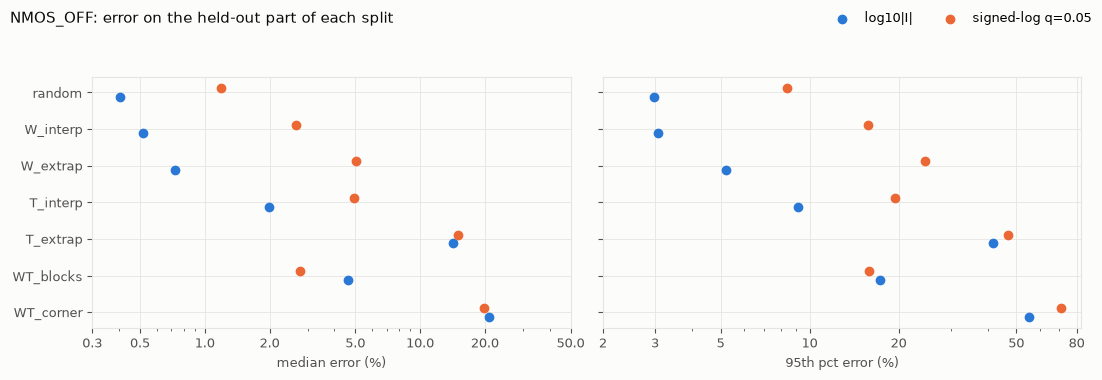

In [19]:
# Median and 95th percentile error per split (NMOS_OFF, log10|I| target vs signed-log target)
from matplotlib.ticker import NullFormatter, ScalarFormatter
order = o.SCHEMES[::-1]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, metric in zip(axes, ["test median err %", "test 95th pct err %"]):
    for method, color, dy in (("log10|I|", BLUE, -0.12), ("signed-log q=0.05", ORANGE, 0.12)):
        d = S[S.method == method].set_index("scheme")
        ys = [order.index(s) + dy for s in d.index]
        ax.scatter(d[metric], ys, s=36, color=color, label=method, zorder=3)
    ax.set(xscale="log", xlabel=metric.replace("test ", "").replace(" err %", " error (%)"))
    ax.set_xticks([0.3, 0.5, 1, 2, 5, 10, 20, 50] if "median" in metric else [2, 3, 5, 10, 20, 50, 80])
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_yticks(range(len(order)), order)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2)
fig.suptitle("NMOS_OFF: error on the held-out part of each split", x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(PLOT_DIR / "nmos_off_structured_splits.png", dpi=150)
plt.show()

### 4c. Other cases

The same splits for PMOS_OFF (patience 3000, like NMOS_OFF) and for the two ON cases (patience 300 as in the notebooks, which do not stall: their notebook models
stopped early at 0.22 % and 0.35 %). The ON runs are therefore not trained under exactly the same rule as the OFF runs.

In [20]:
# All four cases on every split (log10|I| target, MLP 128-64-32-16, no Kirchhoff term, runs that trained all 3000 epochs)
R = RUNS[(RUNS.target == "log") & (RUNS.lam == 0) & (RUNS.seed == SEED) & (RUNS.hidden == "128-64-32-16") & (RUNS.full | RUNS.case.isin(["NMOS_ON", "PMOS_ON"]))].copy()
R["scheme"] = pd.Categorical(R["scheme"], o.SCHEMES, ordered=True)
cols = ["test median err %", "test 95th pct err %", "test mean err %"]
piv = R.pivot_table(index="scheme", columns="case", values=cols, observed=True)
piv.columns = [f"{c.replace('test ', '').replace(' err %', '')} | {case}" for c, case in piv.columns]
piv = piv[sorted(piv.columns, key=lambda s: (["median", "95th pct", "mean"].index(s.split(" | ")[0]), s))]
piv

,median | NMOS_OFF,median | NMOS_ON,median | PMOS_OFF,median | PMOS_ON,95th pct | NMOS_OFF,95th pct | NMOS_ON,95th pct | PMOS_OFF,95th pct | PMOS_ON,mean | NMOS_OFF,mean | NMOS_ON,mean | PMOS_OFF,mean | PMOS_ON
scheme,,,,,,,,,,,,
random,0.4032,NaN,NaN,NaN,2.969,NaN,NaN,NaN,6.89,NaN,NaN,NaN
W_interp,0.5189,0.9064,1.285,0.3745,3.079,3.146,5.323,1.534,6.79,1.515,5.138,0.599
W_extrap,0.7243,1.241,1.47,0.4608,5.198,5.684,7.014,2.109,7.734,1.982,4.485,0.7659
T_interp,1.984,0.6527,0.5072,0.2289,9.16,2.937,2.628,1.224,3.662,1.019,1.863,0.442
T_extrap,14.18,0.5199,16.64,0.6255,41.81,3.945,53.81,3.421,62.72,1.057,61.67,1.041
WT_blocks,4.62,0.651,0.9432,0.2636,17.31,2.559,4.097,1.183,8.294,0.9559,4.389,0.4029
WT_corner,20.92,2.397,24.15,0.9188,55.04,11.14,46.59,4.702,85.95,3.593,29.48,1.407


## 5. A robust loss, and other training choices

The networks minimise the mean-squared error of `log10 |I|`, and keep the epoch with the lowest validation MSE. The near-cancelled rows have a log error of several decades (the target dives and the network cannot follow it), so under MSE they carry a
weight that grows with the square of the error and they steer the choice of the epoch, which could explain the seed lottery of section 3a. A **Huber loss** (quadratic below a transition width β in standardized log units, linear above) limits that influence.
Nothing else changes: same network, features, split and optimizer, 3000 epochs. β was searched on the validation set (the sweep below: 0.2 to 0.002); the table shows the test set, per-seed medians on the right.

In [21]:
# 5a. Loss function, schedule: NMOS_OFF, random split, log10|I| target, 3000 epochs, same network. Test set; per-seed medians on the right.
V = RUNS_ALL[(RUNS_ALL.case == "NMOS_OFF") & (RUNS_ALL.scheme == "random") & (RUNS_ALL.target == "log") & (RUNS_ALL.hidden == "128-64-32-16")
             & RUNS_ALL.full & (RUNS_ALL.n_train == 16000)].drop_duplicates(["variant", "lam", "seed"]).copy()
V["variant"] = V["variant"] + np.where(V["lam"] > 0, " + Kirchhoff loss", "")
per_seed = V.pivot(index="variant", columns="seed", values="test median err %")
per_seed.columns = [f"median, seed {c}" for c in per_seed.columns]
summary = V.groupby("variant").agg(runs=("seed", "size"), **{"median (mean of seeds)": ("test median err %", "mean"),
                                   "95th pct": ("test 95th pct err %", "mean"), "mean err": ("test mean err %", "mean"),
                                   "floored mean": ("test floored mean err %", "mean"), "sum err": ("test sum err %", "mean"),
                                   "id mean abs err (A)": ("test id mean abs err (A)", "mean"), "val median": ("val median err %", "mean")})
tab5 = summary.join(per_seed)
tab5.loc[sorted(tab5.index, key=lambda v: (v != "log10|I|", v))]

,runs,median (mean of seeds),95th pct,mean err,floored mean,sum err,id mean abs err (A),val median,"median, seed 12175305","median, seed 12175306","median, seed 12175307","median, seed 12175308","median, seed 12175309"
variant,,,,,,,,,,,,,
log10|I|,5,0.6494,3.899,8.4,1.474,1.042,9.48e-11,0.6378,0.4032,1.077,0.6161,0.8004,0.3508
"log10|I| + Huber loss, beta 0.002",2,0.1279,1.076,5.722,0.6064,0.3195,3.289e-11,0.1242,0.1299,0.1259,NaN,NaN,NaN
"log10|I| + Huber loss, beta 0.005",2,0.1613,1.209,5.37,0.6027,0.3384,3.395e-11,0.1605,0.1659,0.1567,NaN,NaN,NaN
"log10|I| + Huber loss, beta 0.01",2,0.1731,1.174,4.413,1.127,0.3469,3.635e-11,0.1758,0.1707,0.1756,NaN,NaN,NaN
"log10|I| + Huber loss, beta 0.02",2,0.2451,1.429,4.231,0.6855,0.4597,4.491e-11,0.2431,0.2197,0.2704,NaN,NaN,NaN
"log10|I| + Huber loss, beta 0.05",3,0.2805,1.714,3.607,0.7549,0.5132,5.158e-11,0.2803,0.248,0.3236,0.2699,NaN,NaN
"log10|I| + Huber loss, beta 0.05 + cosine schedule",2,0.2177,1.429,4.491e+08,4.491e+08,1.333e+07,0.000123,0.2126,0.2123,0.2232,NaN,NaN,NaN
"log10|I| + Huber loss, beta 0.1",2,0.3982,2.277,5.342,1.071,0.6592,6.665e-11,0.3873,0.4353,0.3612,NaN,NaN,NaN
"log10|I| + Huber loss, beta 0.2",2,0.3417,2.232,4.507,0.9155,0.6072,5.731e-11,0.3509,0.3068,0.3765,NaN,NaN,NaN


### 5b. The worst test row

The typical error falls with the Huber loss and its seed lottery disappears, but the **mean** does not improve in proportion: the worst test row is the same in every run, MSE or Huber (the near-cancelled `is` of SPICE value 1.57e-13 A, predicted
1.9e-11 – 1.0e-10 A) and alone contributes 1.5 – 8 points of the mean. Without it the mean is 1.0 – 2.1 % for the Huber runs and 2.3 – 3.2 % for MSE. The last row is a Huber run with a cosine learning-rate decay whose median error is good (0.22 %) but in which one test row
was predicted as 14 A instead of 2e-10 A (a blow-up of that network, not an out-of-range input: its features are inside the training range); no plain-Huber run did that, and the final selection rejects any candidate whose worst validation prediction is off by more than 6 decades.

In [22]:
# 5b. The worst test row: the same near-cancelled row in every run. Mean error with and without it.
import glob
rows = []
np.seterr(divide="ignore")
def addrow(label, tag):
    z = np.load(STUDY / "preds" / f"{tag}.npz")
    P, T, idx = z["test"].astype(float), z["test_true"].astype(float), z["test_idx"]
    rel = np.abs(np.abs(P) / np.abs(T) - 1) * 100
    r, c = np.unravel_index(rel.argmax(), rel.shape)
    rows.append({"run": label, "median %": np.median(rel), "mean %": rel.mean(), "worst row": int(idx[r]), "worst current": o.OUTPUT_COLS[c],
                 "its |I| SPICE (A)": abs(T[r, c]), "its |I| ML (A)": abs(P[r, c]), "its error %": rel.max(),
                 "mean % without it": np.delete(rel.ravel(), rel.argmax()).mean(),
                 "worst |log10 error| (decades)": float(np.nanmax(np.abs(np.log10(np.abs(P) / np.abs(T)))[np.isfinite(np.log10(np.abs(P) / np.abs(T)))]))})
for k in range(3):
    for label, kw in (("MSE", {}), ("Huber beta 0.05", dict(loss_kind="huber")), ("Huber beta 0.01", dict(loss_kind="huber", huber_beta=0.01))):
        tag = o.run_tag("NMOS_OFF", "random", "log", 0.01, 0.0, SEED + k, patience=3000 if (k or kw) else 300, **kw)
        if (STUDY / "preds" / f"{tag}.npz").exists():
            addrow(f"{label}, seed {SEED + k}", tag)
tag = o.run_tag("NMOS_OFF", "random", "log", 0.01, 0.0, SEED + 1, patience=3000, loss_kind="huber", sched_kind="cosine")
if (STUDY / "preds" / f"{tag}.npz").exists():
    addrow(f"Huber beta 0.05 + cosine, seed {SEED + 1}", tag)
pd.DataFrame(rows).set_index("run")

,median %,mean %,worst row,worst current,its |I| SPICE (A),its |I| ML (A),its error %,mean % without it,worst |log10 error| (decades)
run,,,,,,,,,
"MSE, seed 12175305",0.3795,6.89,13855,is,1.571e-13,5.766e-11,3.66e+04,2.315,2.565
"Huber beta 0.05, seed 12175305",0.2214,3.926,13855,is,1.571e-13,3.163e-11,2.003e+04,1.422,2.304
"Huber beta 0.01, seed 12175305",0.1568,4.882,13855,is,1.571e-13,3.458e-11,2.191e+04,2.144,9.884
"MSE, seed 12175306",0.9667,7.079,13855,is,1.571e-13,4.901e-11,3.109e+04,3.193,2.494
"Huber beta 0.05, seed 12175306",0.2898,3.629,13855,is,1.571e-13,3.073e-11,1.946e+04,1.197,2.291
"Huber beta 0.01, seed 12175306",0.157,3.944,13855,is,1.571e-13,3.249e-11,2.058e+04,1.372,2.315
"MSE, seed 12175307",0.5678,10.37,13855,is,1.571e-13,1.016e-10,6.455e+04,2.307,2.811
"Huber beta 0.05, seed 12175307",0.2418,3.266,13855,is,1.571e-13,2.597e-11,1.643e+04,1.213,2.218
"Huber beta 0.05 + cosine, seed 12175306",0.2082,8.982e+08,14218,is,2.09e-10,14.42,6.9e+12,3.565e+07,10.84


### 5c. The other three cases

Huber loss with β = 0.05 (seed 12175305) next to the models of the training notebooks (test set). All three improve in median and 95th percentile; the Huber loss was not tuned on them.

In [23]:
# 5c. The other three cases with the Huber loss (beta 0.05, seed 12175305, 3000 epochs) next to the notebooks' models (test set)
rows = []
for case, official in (("NMOS_ON", "test"), ("PMOS_ON", "test"), ("PMOS_OFF", "test")):
    r = json.loads((STUDY / "runs" / f"{o.run_tag(case, 'random', 'log', 0.01, 0.0, SEED, patience=3000, loss_kind='huber')}.json").read_text())
    ref = pd.read_csv(ROOT / "ML_Models" / "Results" / "test_results.csv")
    ref = ref[(ref["case"] == case) & (ref["current"] == "average")].iloc[0]
    a = r["test"]["average"]
    rows.append({"case": case, "notebook model: median / 95th / mean %": f"{ref['median err %']:.2f} / {ref['95th pct err %']:.2f} / {ref['mean err %']:.2f}",
                 "Huber loss: median / 95th / mean %": f"{a['median err %']:.2f} / {a['95th pct err %']:.2f} / {a['mean err %']:.2f}",
                 "Huber loss, sum err %": a["sum err %"]})
pd.DataFrame(rows).set_index("case")

,notebook model: median / 95th / mean %,Huber loss: median / 95th / mean %,"Huber loss, sum err %"
case,,,
NMOS_ON,0.22 / 1.27 / 0.77,0.16 / 0.85 / 0.68,0.2158
PMOS_ON,0.35 / 1.56 / 0.65,0.20 / 0.93 / 0.47,0.2363
PMOS_OFF,0.36 / 2.13 / 1.30,0.20 / 1.12 / 0.93,0.4022


### 5d. Does more training data help?

The Huber model (β = 0.002) trained on 4,000, 8,000, 12,000 and 16,000 of the training rows (same validation and test rows, seed 12175305). The test median falls 0.33 → 0.22 → 0.14 → 0.13 % and the 95th percentile 3.7 → 2.4 → 1.35 → 1.16 %: the gain flattens between 12,000 and 16,000 rows, so more samples than the 20,000 of the assignment are unlikely to be the main lever for the typical error (not tested beyond 16,000 rows). The mean (15 → 7.3 → 3.7 → 5.7 %) mainly reflects which near-cancelled rows are in the test set.

In [24]:
# 5d. Learning curve of the Huber model (beta from the validation sweep, seed 12175305, 3000 epochs): how much does more training data help?
LC = RUNS_ALL[(RUNS_ALL.case == "NMOS_OFF") & (RUNS_ALL.scheme == "random") & (RUNS_ALL.target == "log") & (RUNS_ALL.lam == 0) & (RUNS_ALL.hidden == "128-64-32-16")
              & RUNS_ALL.full & (RUNS_ALL.seed == SEED) & (RUNS_ALL.loss_kind == "huber") & (RUNS_ALL.sched_kind == "plateau")].copy()
LC = LC[LC["huber_beta"] == LC.loc[LC["n_train"] == 4000, "huber_beta"].max()] if (LC["n_train"] == 4000).any() else LC[LC["huber_beta"] == 0.01]
LC.sort_values("n_train").set_index("n_train")[["val median err %", "test median err %", "test 95th pct err %", "test mean err %",
                                                "test sum err %", "test id mean abs err (A)", "train median err %"]]

,val median err %,test median err %,test 95th pct err %,test mean err %,test sum err %,test id mean abs err (A),train median err %
n_train,,,,,,,
4000,0.3358,0.3276,3.708,15.45,0.7964,7.379e-11,0.1668
8000,0.2191,0.2212,2.417,7.312,0.5586,5.113e-11,0.173
12000,0.1435,0.1436,1.347,3.745,0.372,3.482e-11,0.1171
16000,0.1293,0.1299,1.159,5.714,0.3249,3.459e-11,0.1137


### 5e. Final Huber models

Both seeds of each case were trained with the width chosen on validation (β = 0.002), the better one on the validation median (without a blown-up prediction) is `Saved_Models/huber/<case>.pt`, and `Results/huber_test_results.csv`
compares it with the official model on the test set (made by `ML_Models/Scripts/export_huber_models.py`). The official models are unchanged.

In [25]:
# 5e. The final Huber models of the four cases (Saved_Models/huber/) next to the official ones: test set, made by export_huber_models.py
f = ROOT / "ML_Models" / "Results" / "huber_test_results.csv"
if f.exists():
    res = pd.read_csv(f)
    res = res[res["set"] == "test"].drop(columns="set")
    display(res.set_index(["case", "model"]))
else:
    print("run ML_Models/Scripts/export_huber_models.py first")

R2 (log|I|)  median err %  95th pct err %  mean err % id median / 95th / mean % is median / 95th / mean %  sum err % (A-weighted)  mean abs err id (A)  \
case     model                                                                                                                                                                          
NMOS_ON  official (notebooks)       0.9997        0.2248           1.272      0.7714        0.20 / 1.02 / 0.72        0.20 / 1.09 / 1.21                  0.1864            1.978e-07   
         Huber loss                 0.9997       0.09896           0.617      0.5758        0.08 / 0.45 / 0.53        0.08 / 0.46 / 1.11                 0.08033            8.738e-08   
NMOS_OFF official (notebooks)       0.9852        0.3974           2.604       6.668        0.55 / 3.58 / 4.83       0.54 / 3.26 / 20.29                  0.7598            6.511e-11   
         Huber loss                 0.9923        0.1259          0.9923        5.73        0.19 / 1.52 / 2.27       0.18 / 1.29 / 20.09                  0.3486            3.118e-11   
PMOS_ON  official (notebooks)       0.9998        0.3476           1.562      0.6511        0.34 / 1.34 / 0.92        0.34 / 1.39 / 0.51                  0.3572            1.675e-07   
         Huber loss                 0.9998       0.09422          0.5985      0.3116        0.07 / 0.39 / 0.55        0.07 / 0.43 / 0.19                 0.07587            3.413e-08   
PMOS_OFF official (notebooks)       0.9921        0.3573            2.13         1.3        0.49 / 2.90 / 2.17        0.48 / 2.67 / 1.18                  0.7084              5.2e-11   
         Huber loss                 0.9964        0.1183          0.8607      0.8513        0.15 / 1.17 / 2.02        0.16 / 1.22 / 0.68                  0.2503            1.813e-11   

                               worst |log10 error| (decades)  
case     model                                                
NMOS_ON  official (notebooks)                         0.9236  
         Huber loss                                    1.109  
NMOS_OFF official (notebooks)                          2.584  
         Huber loss                                    2.593  
PMOS_ON  official (notebooks)                         0.8916  
         Huber loss                                   0.8956  
PMOS_OFF official (notebooks)                          1.214  
         Huber loss                                    1.411

## Conclusions

1. **The NMOS_OFF mean error is a property of the metric, not of typical accuracy.** It comes from the few rows where `id` or `is` is almost cancelled; there the model's
   absolute error (of the order of 0.1 % – 0.3 % of the largest current, 65 pA on average over the test set) is unchanged but the percentage explodes. The ampere-weighted error is 0.76 %, the median 0.40 %, the 95th percentile 2.6 %.
2. **A Huber loss is the change that helps:** median 0.40 % → 0.13 %, 95th percentile 2.6 – 3.0 % → 1.0 – 1.2 %, seed spread gone, and an improvement in the other three cases too (section 5). It does not remove the single
   near-cancelled row that sets the mean, and it needs a check for blown-up predictions (one cosine-schedule run predicted 14 A for 2e-10 A).
3. **A signed-log target does not fix it.** It lowers the mean of one run, never the median or the ampere error, and makes training harder (underfit models, sign errors on 0.1 % – 1.0 % of the `id` / `is` values). The deriving-from-Kirchhoff, bigger-network and
   ensemble alternatives do not lower the mean either; an ensemble of full-length runs does remove the seed lottery (median 0.35 %, 95th percentile 2.2 %).
4. **Where accuracy would have to improve to lower the tail:** the base absolute accuracy of the network on the large terms (of the order of 0.1 % – 0.3 % of the row's largest current), and the reproducibility of training (seed spread 3×). More samples near sign changes, a loss that weights the near-cancelled rows, and the structured splits with the Huber loss are untested.
5. **Generalization:** interpolation in width or in temperature (held-out bands of 0.5 in W / L or 10 °C) is within the seed noise of the random split, and widths even extrapolate; extrapolation in temperature is not
   possible: about 10× worse for `id`, `is`, `ig` and about 100× worse for the body current `ib` above the trained range (`ib` is flat below 85 °C and only rises above about 90 °C, which the training set does not show). The ranges of Part B / C (VDD ± 10 %, −40 – 125 °C, W / L 1 – 8)
   coincide with the training ranges, so the interior accuracy applies there; the temperature range must not be reduced in training.